# Dataset Analysis: BESSTIE

This section presents an exploratory analysis of the BESSTIE dataset, which is used for sequence classification tasks involving sentiment analysis and sarcasm detection across multiple varieties of English.

The analysis focuses on understanding:

- Class distribution for sentiment and sarcasm
- Distribution across English varieties (en-UK, en-AU, en-IN)
- Source distribution (Google Places vs Reddit)
- Linguistically motivated insights, including token-level variation

This forms the foundation for designing and justifying subsequent modelling experiments.

## Import and Setup 

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

sns.set(style="whitegrid")

## Loading Dataset 

The dataset is loaded from the locally stored CSV files corresponding to the predefined training, validation, and test splits.

In [7]:
base_path = "../data/raw"

train_df = pd.read_csv(os.path.join(base_path, "besstie_train.csv"))
val_df = pd.read_csv(os.path.join(base_path, "besstie_validation.csv"))
test_df = pd.read_csv(os.path.join(base_path, "besstie_test.csv"))

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (3747, 5)
Validation shape: (313, 5)
Test shape: (2183, 5)


## Dataset Overview

We inspect the structure of the dataset, including feature columns and example records.

In [8]:
train_df.head()

,text,variety,source,Sentiment,Sarcasm
0,I'm a member of the Green Party but I'll be vo...,en-UK,Reddit,0.0,0.0
1,Yeah it blew out to 3x what it was budgeted fo...,en-AU,Reddit,0.0,1.0
2,"Food was pretty great. A little dry, but I am ...",en-AU,Google,1.0,0.0
3,Firstly the staff seemed as if they did n't wa...,en-UK,Google,0.0,0.0
4,We came for lunch and enjoyed the food we orde...,en-UK,Google,1.0,0.0


The dataset consists of the following key attributes:

- **text**: the input sentence or review
- **variety**: the English dialect (en-UK, en-AU, en-IN)
- **source**: the data source (Google Places or Reddit)
- **Sentiment**: binary label (0 = negative, 1 = positive)
- **Sarcasm**: binary label (0 = not sarcastic, 1 = sarcastic)

These attributes enable both classification and linguistic analysis across dialects.

## Sentiment Distribution

We analyse the distribution of sentiment labels to identify any class imbalance in the dataset.

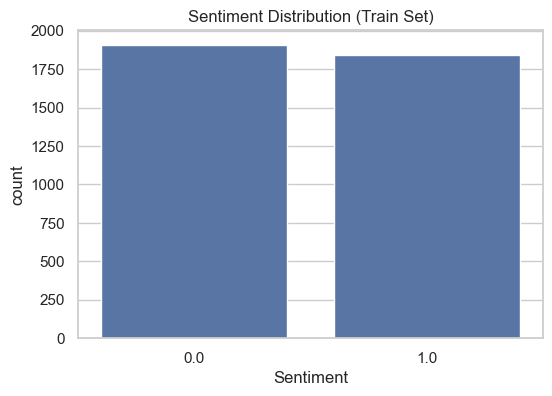

Sentiment
0.0    0.50894
1.0    0.49106
Name: proportion, dtype: float64

In [9]:
plt.figure(figsize=(6,4))
sns.countplot(data=train_df, x="Sentiment")
plt.title("Sentiment Distribution (Train Set)")
plt.show()

train_df["Sentiment"].value_counts(normalize=True)

The sentiment distribution indicates a well-balanced dataset, making it suitable for training classification models without additional preprocessing for class imbalance.

## Sarcasm Distribution

Sarcasm detection is typically more challenging due to its reliance on implicit meaning and contextual cues. We analyse its distribution below.

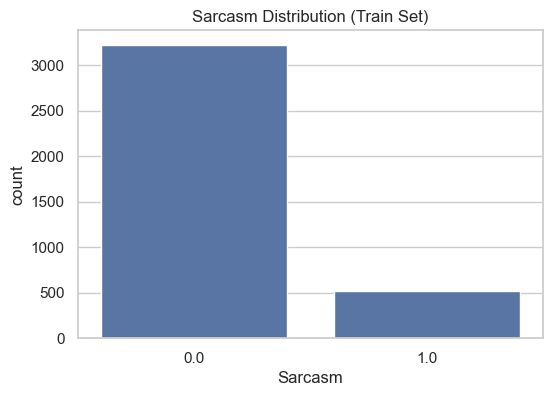

Sarcasm
0.0    0.860155
1.0    0.139845
Name: proportion, dtype: float64

In [10]:
plt.figure(figsize=(6,4))
sns.countplot(data=train_df, x="Sarcasm")
plt.title("Sarcasm Distribution (Train Set)")
plt.show()

train_df["Sarcasm"].value_counts(normalize=True)

Sarcasm instances (13.98%) are significantly underrepresented compared to non-sarcastic instances (86.02%), indicating a strong class imbalance in the dataset.

This imbalance reflects real-world language patterns but introduces bias in model learning, making it essential to rely on evaluation metrics beyond accuracy to properly assess performance on the minority class.

## Distribution Across English Varieties

We analyse how data is distributed across the three English varieties: British (en-UK), Australian (en-AU), and Indian (en-IN).

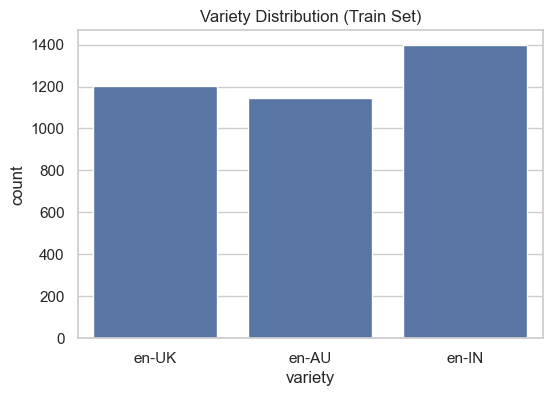

variety
en-IN    1399
en-UK    1203
en-AU    1145
Name: count, dtype: int64

In [11]:
plt.figure(figsize=(6,4))
sns.countplot(data=train_df, x="variety")
plt.title("Variety Distribution (Train Set)")
plt.show()

train_df["variety"].value_counts()

The dataset includes multiple English varieties, with en-IN having the highest representation, followed by en-UK and en-AU.

Although broadly balanced, such variations may introduce linguistic diversity that impacts model generalisation across different language contexts.

Differences in representation may influence model learning and contribute to the “variety gap”, where models trained on one dialect may not generalise effectively to others.

## Source Distribution

The dataset contains text from two sources: Google Places and Reddit. These sources may differ in tone, style, and linguistic characteristics.

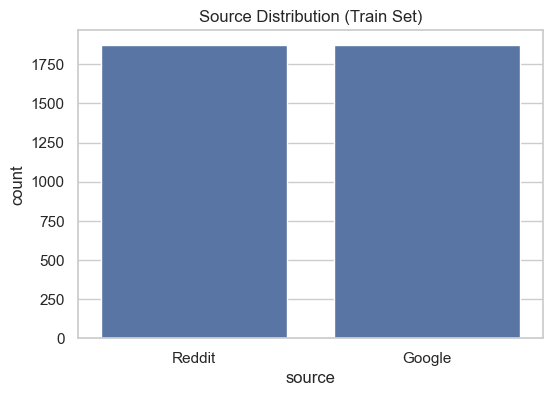

source
Google    1874
Reddit    1873
Name: count, dtype: int64

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(data=train_df, x="source")
plt.title("Source Distribution (Train Set)")
plt.show()

train_df["source"].value_counts()

The dataset is evenly distributed across sources, with Google (1874) and Reddit (1873) contributing almost identical sample counts.

This balanced distribution reduces source-specific bias and supports better model generalisation across different text domains.

## Cross-Analysis: Variety vs Sentiment and Sarcasm

We further analyse how sentiment and sarcasm are distributed across different English varieties.

In [13]:
pd.crosstab(train_df["variety"], train_df["Sentiment"], normalize="index")

Sentiment,0.0,1.0
variety,,
en-AU,0.552838,0.447162
en-IN,0.492495,0.507505
en-UK,0.486284,0.513716


In [14]:
pd.crosstab(train_df["variety"], train_df["Sarcasm"], normalize="index")

Sarcasm,0.0,1.0
variety,,
en-AU,0.705677,0.294323
en-IN,0.932094,0.067906
en-UK,0.923525,0.076475


Sentiment remains relatively balanced across varieties, with minor shifts in polarity between regions.

In contrast, sarcasm shows notable variation, with en-AU containing a higher proportion of sarcastic instances compared to en-IN and en-UK.

This indicates that linguistic variation influences label distribution, which may affect model robustness across different English contexts

## Linguistic Analysis: Part-of-Speech Distribution

To better understand syntactic variation across English dialects, we analyse the distribution of Part-of-Speech (POS) tags. Differences in POS usage may reflect linguistic and stylistic variation across varieties, which can influence model performance.

In [19]:
import spacy
nlp = spacy.load("en_core_web_sm")

def get_pos_distribution(texts, sample_size=500):
    pos_counts = {}
    
    for text in texts[:sample_size]:
        doc = nlp(str(text))
        for token in doc:
            pos = token.pos_
            pos_counts[pos] = pos_counts.get(pos, 0) + 1
            
    return pos_counts

In [20]:
uk_texts = train_df[train_df["variety"] == "en-UK"]["text"].tolist()
au_texts = train_df[train_df["variety"] == "en-AU"]["text"].tolist()
in_texts = train_df[train_df["variety"] == "en-IN"]["text"].tolist()

uk_pos = get_pos_distribution(uk_texts)
au_pos = get_pos_distribution(au_texts)
in_pos = get_pos_distribution(in_texts)

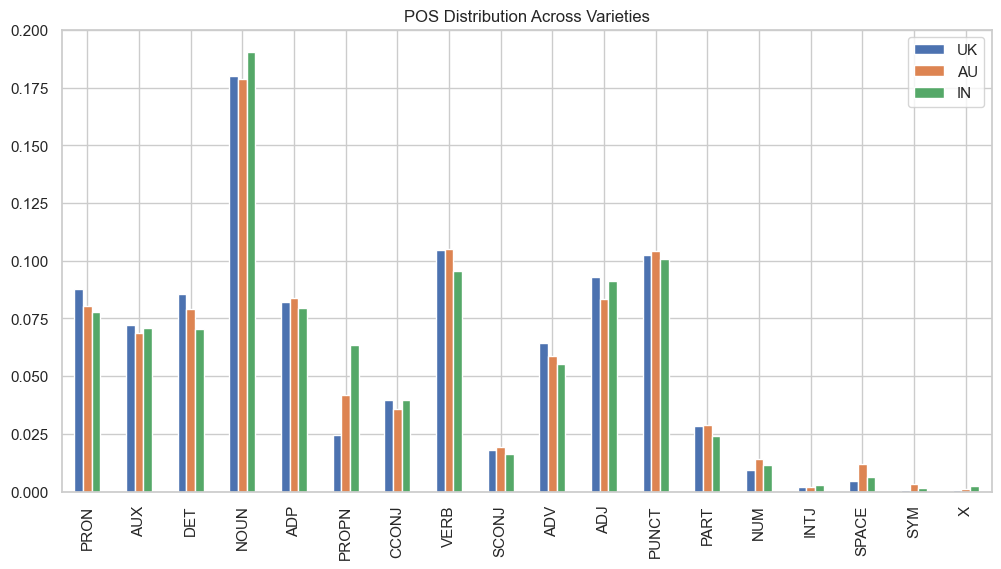

In [21]:
# Converting to Dataframe 

pos_df = pd.DataFrame([uk_pos, au_pos, in_pos], index=["UK", "AU", "IN"]).fillna(0)
pos_df = pos_df.div(pos_df.sum(axis=1), axis=0)

pos_df.T.plot(kind="bar", figsize=(12,6))
plt.title("POS Distribution Across Varieties")
plt.show()

The POS distribution remains broadly consistent across all English varieties, with nouns, verbs, and punctuation forming the dominant components.

Minor variations are observed, such as a higher proportion of proper nouns in en-IN and slightly higher verbs and punctuation in en-AU and en-UK. However, these differences are subtle and do not significantly alter the overall linguistic structure.

This consistency suggests that while surface-level linguistic variation exists, the underlying grammatical patterns remain stable, supporting model generalisation across different English varieties.

## Linguistic Analysis: Vocabulary Overlap

To examine lexical variation across English varieties, we compute vocabulary overlap between dialects. This provides a simple measure of linguistic similarity and helps us estimate whether varieties share similar lexical items or differ substantially in token usage.

A lower overlap may indicate greater linguistic distance, which can negatively affect cross-variety model transfer.

In [22]:
# Simple vocaubluary extraction 

import re

def tokenize_simple(text):
    text = str(text).lower()
    tokens = re.findall(r"\b[a-zA-Z']+\b", text)
    return tokens

def build_vocabulary(texts):
    vocab = set()
    for text in texts:
        vocab.update(tokenize_simple(text))
    return vocab

In [23]:
uk_vocab = build_vocabulary(uk_texts)
au_vocab = build_vocabulary(au_texts)
in_vocab = build_vocabulary(in_texts)

print("UK vocabulary size:", len(uk_vocab))
print("AU vocabulary size:", len(au_vocab))
print("IN vocabulary size:", len(in_vocab))

UK vocabulary size: 7392
AU vocabulary size: 8003
IN vocabulary size: 7223


In [24]:
# Jaccard similarity 

def jaccard_similarity(set1, set2):
    intersection = len(set1.intersection(set2))
    union = len(set1.union(set2))
    return intersection / union if union != 0 else 0

j_uk_au = jaccard_similarity(uk_vocab, au_vocab)
j_uk_in = jaccard_similarity(uk_vocab, in_vocab)
j_au_in = jaccard_similarity(au_vocab, in_vocab)

print(f"Jaccard Similarity (UK, AU): {j_uk_au:.4f}")
print(f"Jaccard Similarity (UK, IN): {j_uk_in:.4f}")
print(f"Jaccard Similarity (AU, IN): {j_au_in:.4f}")

Jaccard Similarity (UK, AU): 0.3510
Jaccard Similarity (UK, IN): 0.2966
Jaccard Similarity (AU, IN): 0.2906


In [25]:
jaccard_df = pd.DataFrame({
    "Pair": ["UK-AU", "UK-IN", "AU-IN"],
    "Jaccard Similarity": [j_uk_au, j_uk_in, j_au_in]
})

jaccard_df

,Pair,Jaccard Similarity
0,UK-AU,0.351031
1,UK-IN,0.296576
2,AU-IN,0.290558


The Jaccard similarity scores indicate a moderate degree of lexical overlap across the three English varieties. Among the pairs, UK–AU exhibits the highest similarity (0.351), while UK–IN (0.297) and AU–IN (0.291) show comparatively lower overlap.

This suggests that British and Australian English share a more similar lexical distribution, whereas Indian English demonstrates greater lexical divergence. This divergence may be attributed to factors such as code-mixing, localised expressions, and domain-specific vocabulary.

From a modelling perspective, such lexical variation is particularly important. Classical approaches based on word frequency (e.g., TF-IDF) are more sensitive to vocabulary mismatch, and therefore may struggle to generalise across dialects. In contrast, contextual models such as transformers are expected to be more robust, as they can capture semantic relationships beyond exact token matches.

These findings provide a linguistic explanation for the expected “variety gap” in cross-variety evaluation.

## Token-Level Variation and Linguistic Diversity

To further understand dialectal variation, we examine token-level differences across English varieties. This includes slang, colloquial expressions, and potential code-mixed tokens, which may not be uniformly represented across dialects.

Such variation is particularly important for NLP models, as differences at the token level directly influence tokenisation, feature extraction, and embedding representations.

In [28]:
# Sample token 

def sample_texts(df, variety, n=5):
    return df[df["variety"] == variety]["text"].sample(n, random_state=42).tolist()

print("UK Samples:\n")
for t in sample_texts(train_df, "en-UK"):
    print("-", t)

print("\nAU Samples:\n")
for t in sample_texts(train_df, "en-AU"):
    print("-", t)

print("\nIN Samples:\n")
for t in sample_texts(train_df, "en-IN"):
    print("-", t)

UK Samples:

- Beautiful cathedral. It undergoing a lot of renovation work currently and there are some interesting updates on this around the building. It not a very serene space as there are lots of tourists around and about but it is still a vast and impressive space. Be warned lots of steps, it quite cold even in the summer and it is very expensive to get in
- Mate, he is not posh in the slightest. 
Most of us don't like the guy but let's not tell half-truths.
- Nice clean spacious cafe. Nice cup of tea, black pudding available as an extra. Healthy portion of beans. Poor quality sausage and slightly overdone egg will stop me rushing back for breakfast but I'm keen to try the lunch menu.
- That's a tough wall. I reckon de pfeffel Johnson is probably the highest score because he was the most image obsessed, and therefore most recognisable to whoever lacks the cunning to avoid the people who do the surveys for Pointless
- Can't we just say they should both burn in hell together?

AU S

In [29]:
# Unusual Tokens 

def find_unusual_tokens(counter, threshold=5):
    return [word for word, count in counter.items() if count <= threshold]

print("Sample rare IN tokens:", find_unusual_tokens(in_counter)[:20])

Sample rare IN tokens: ['chats', 'vd', 'lately', 'demand', 'crowds', 'chowkidar', 'servant', 'chkn', 'qty', 'sells', 'haleem', 'sale', 'airconditioned', 'shawarma', 'collection', "jhandvi's", 'bots', 'claiming', 'kriti', 'ananya']




The sampled text instances reveal clear lexical and stylistic differences across the three English varieties. UK English includes colloquial expressions such as “mate” alongside culturally specific vocabulary such as “black pudding”, while Australian English exhibits informal and regionally marked slang, for example “batshit”. Indian English shows greater lexical divergence through the presence of culturally specific terms such as “namkeen”, “kachori”, and “BJP”, as well as non-standard or noisy spellings such as “adhar” and “reghit”.

These observations suggest that dialectal variation in the dataset occurs not only at the level of meaning, but also at the token level. This is important for NLP modelling because classical approaches such as TF-IDF rely heavily on exact lexical overlap, whereas transformer-based models are better positioned to handle such variation through subword tokenisation and contextual representations.

Overall, the token-level evidence supports the hypothesis that lexical distance may contribute to the expected variety gap in cross-variety classification.

## Key Observations 

Overall, the dataset demonstrates a well-structured composition, with balanced sentiment and source distributions, and a reasonably even spread across different English varieties. This supports stable learning and reduces the risk of bias from any single domain or class.

However, a pronounced class imbalance in sarcasm introduces a key challenge, as the minority class is underrepresented and harder to learn. Additionally, variations across language varieties highlight the presence of linguistic and cultural differences that influence how sentiment and sarcasm are expressed.

The POS analysis shows that grammatical structures are largely consistent across varieties, with nouns, verbs, and punctuation dominating across all groups. Minor variations (e.g., higher proper noun usage in certain varieties) indicate surface-level differences without significant structural divergence.

Further lexical analysis using Jaccard similarity reveals only moderate vocabulary overlap across varieties, with en-IN being slightly more distinct. Sample text analysis also highlights region-specific expressions, slang, and culturally embedded terms, reinforcing the presence of lexical diversity at the token level.

Together, these findings indicate that while the dataset is suitable for modelling, effective performance will depend on handling class imbalance and ensuring the model can generalise across diverse linguistic, lexical, and stylistic contexts.